# Biến đổi Fourier rời rạc hữu hạn 2 chiều (2D DFT) và nghịch đảo (2D iDFT)

---

## 1) Tín hiệu rời rạc hữu hạn 2D

Xét một ảnh / ma trận / trường mẫu rời rạc hữu hạn:

$$
x[n,m], \quad n = 0,\dots,N-1,\;\; m = 0,\dots,M-1
$$

Trong đó:
- $n$ thường là chỉ số theo trục 1 (ví dụ: thời gian / hàng)
- $m$ là chỉ số theo trục 2 (ví dụ: không gian / cột)

**Giả định ngầm của DFT 2D:**

$$
x[n+N,m]=x[n,m], \qquad x[n,m+M]=x[n,m]
$$

Tức là tín hiệu được xem như **tuần hoàn theo cả hai chiều** với chu kỳ lần lượt là $N$ và $M$.

---

## 2) Định nghĩa 2D DFT

Phổ 2D DFT được định nghĩa:

$$
X[k,\ell]
=
\sum_{n=0}^{N-1}\sum_{m=0}^{M-1}
x[n,m]\; e^{-i2\pi\left(\frac{k n}{N}+\frac{\ell m}{M}\right)}
$$

với:

$$
k=0,\dots,N-1,\qquad \ell=0,\dots,M-1
$$

Ý nghĩa:
- $k$ là chỉ số tần số rời rạc theo chiều $n$
- $\ell$ là chỉ số tần số rời rạc theo chiều $m$

---

## 3) Định nghĩa 2D iDFT (nghịch đảo)

Tái tạo lại $x[n,m]$ từ $X[k,\ell]$:

$$
x[n,m] =
\frac{1}{NM}
\sum_{k=0}^{N-1}\sum_{\ell=0}^{M-1}
X[k,\ell]\; e^{i2\pi\left(\frac{k n}{N}+\frac{\ell m}{M}\right)}
$$

với:

$$
n=0,\dots,N-1,\qquad m=0,\dots,M-1
$$

---

## 4) Tính tách được (Separable)

2D DFT có thể tính bằng hai bước 1D DFT:

1) DFT theo chiều $m$ cho từng hàng  
2) DFT theo chiều $n$ cho từng cột của kết quả

Tức là:

> 2D DFT = DFT theo hàng + DFT theo cột (hoặc ngược lại)

Đây là lý do FFT 2D chạy nhanh: áp dụng FFT 1D hai lần.

---

## 5) Trục tần số theo đơn vị “bin” và theo Hz (nếu cần)

2D DFT định nghĩa theo chỉ số $(k,\ell)$ là đủ.

Nếu bạn muốn đổi sang tần số vật lý:

- Nếu chiều $n$ là thời gian với tần số lấy mẫu $F_s$ (Hz):

$$
v_k = \frac{k}{N}F_s
$$

- Nếu chiều $m$ là không gian với bước lấy mẫu $\Delta z$ (đơn vị chiều dài),
thì tần số không gian (cycles/unit) là:

$$
\kappa_\ell = \frac{\ell}{M\,\Delta z}
$$

---

## 6) Tóm tắt công thức

**2D DFT:**

$$
F[k,\ell] =
\sum_{n=0}^{N-1}\sum_{m=0}^{M-1}
f[n,m]\; e^{-i2\pi\left(\frac{k n}{N}+\frac{\ell m}{M}\right)}
$$

**2D iDFT:**

$$
f[n,m]=
\frac{1}{NM}
\sum_{k=0}^{N-1}\sum_{\ell=0}^{M-1}
F[k,\ell]\; e^{i2\pi\left(\frac{k n}{N}+\frac{\ell m}{M}\right)}
$$

---

## 7) Ghi chú quan trọng (leakage / aliasing trong 2D)

- Nếu dữ liệu không “khép chu kỳ” theo biên (không tuần hoàn thật), DFT 2D sẽ coi biên bị nối lại → dễ gây rò phổ (leakage) và artefact.
- Windowing 2D (nhân cửa sổ theo cả hai chiều) thường dùng để giảm leakage.
- Khi dữ liệu là kết quả của sampling 2D từ tín hiệu liên tục, aliasing xảy ra nếu phổ lặp bị chồng lên nhau.


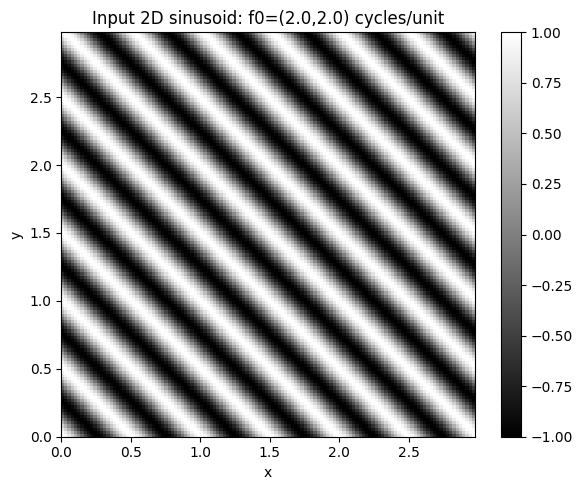

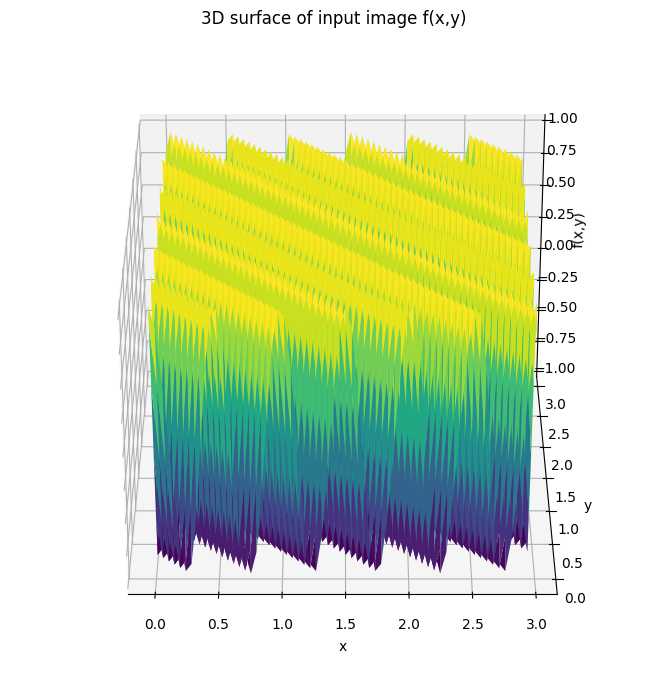

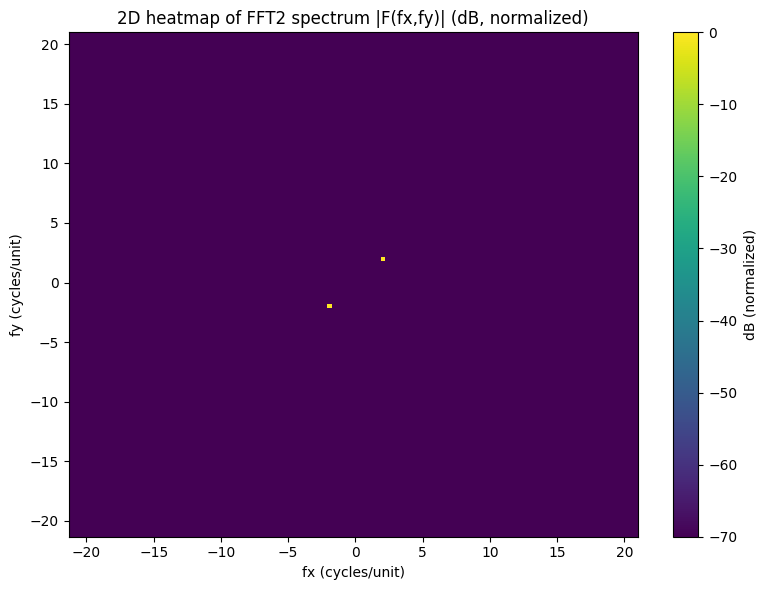

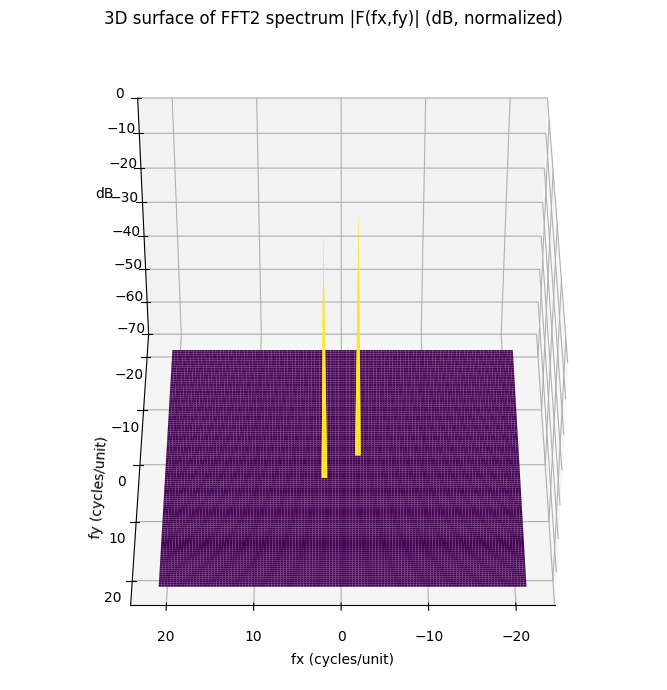

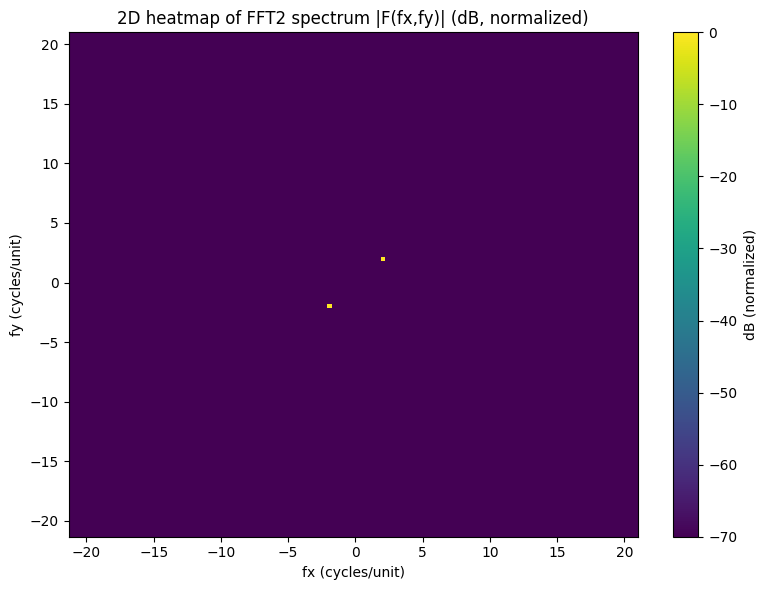

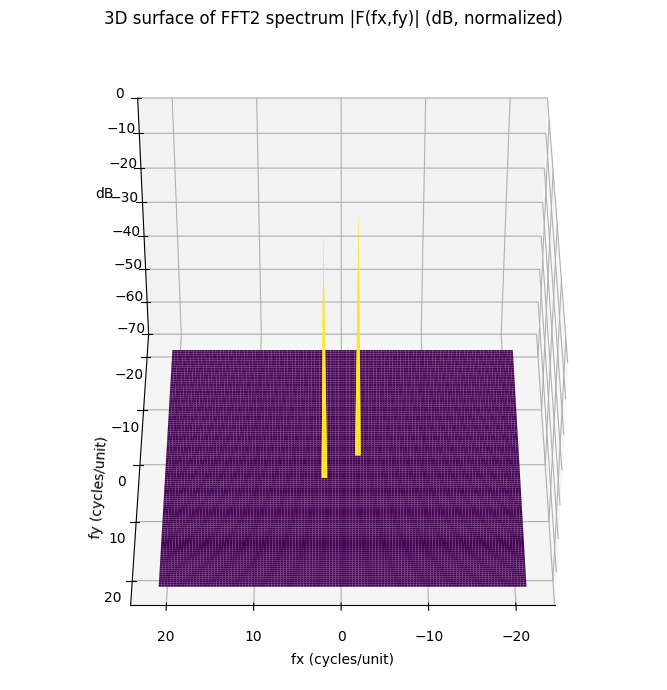

Done. Notes:
- The spatial sinusoid produces two symmetric spectral peaks.
- FFT2 evaluates the Fourier transform only on the DFT grid.
- Definition-based DTFT can evaluate arbitrary frequency locations.
- Sampling causes periodic replication in frequency domain.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401


# ============================================================
# PLOTTING UTILITIES
# ============================================================

# 2D heatmap hiển thị biên độ phổ (linear hoặc dB)
def plot2d_heatmap(Z, x, y, title, xlabel, ylabel,
                   cbar_label="", use_db=False, zlim_db=(-70, 0)):

    plt.figure(figsize=(8, 6))

    if use_db:
        # chuyển sang dB để thấy rõ đỉnh phổ
        Zm = np.abs(Z)
        Zdb = 20 * np.log10(Zm / (Zm.max() + 1e-12) + 1e-12)
        Zdb = np.clip(Zdb, zlim_db[0], zlim_db[1])
        im = plt.imshow(
            Zdb,
            extent=[x.min(), x.max(), y.min(), y.max()],
            origin="lower",
            aspect="auto"
        )
        plt.colorbar(im, label=(cbar_label or "dB (normalized)"))
    else:
        im = plt.imshow(
            Z,
            extent=[x.min(), x.max(), y.min(), y.max()],
            origin="lower",
            aspect="auto"
        )
        plt.colorbar(im, label=(cbar_label or "Magnitude"))

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 3D Surface Plot
# ------------------------------------------------------------

def plot3d_surface(Z, X, Y, title,
                   xlabel, ylabel, zlabel,
                   stride=3,
                   zlim=None,
                   elev=30, azim=-90):

    # giảm mật độ điểm để vẽ nhanh hơn
    Xs = X[::stride, ::stride]
    Ys = Y[::stride, ::stride]
    Zs = Z[::stride, ::stride]

    fig = plt.figure(figsize=(11, 7))
    ax = fig.add_subplot(111, projection="3d")

    ax.plot_surface(
        Xs, Ys, Zs,
        rstride=1, cstride=1,
        linewidth=0,
        antialiased=True,
        cmap="viridis",
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_zlabel(zlabel)

    if zlim is not None:
        ax.set_zlim(zlim[0], zlim[1])

    # điều chỉnh góc nhìn 3D
    ax.view_init(elev=elev, azim=azim)

    plt.tight_layout()
    plt.show()


# Hàm chuyển phổ sang dB
def mag_db(Z, zlim_db=(-70, 0)):
    Zm = np.abs(Z)
    Zdb = 20 * np.log10(Zm / (Zm.max() + 1e-12) + 1e-12)
    return np.clip(Zdb, zlim_db[0], zlim_db[1])


# ============================================================
# GENERATE 2D SINUSOID IMAGE
# ============================================================

def make_sinusoid_2d(Nx, Ny, dx, dy, f0x, f0y, phase=0.0):
    """
    Xây dựng ảnh dạng:
        f(x,y) = cos(2π(f0x x + f0y y) + phase)

    f0x, f0y: tần số không gian (cycles / unit length)
    """

    x = np.arange(Nx) * dx
    y = np.arange(Ny) * dy
    X, Y = np.meshgrid(x, y, indexing="xy")

    img = np.cos(2*np.pi*(f0x*X + f0y*Y) + phase)

    return x, y, img


# ============================================================
# FFT2 (DFT GRID)
# ============================================================

def fft2_spectrum(img, dx, dy):
    """
    Tính phổ bằng FFT2.

    Kết quả tương đương DTFT tại các điểm:
        fx = k / (N dx)
        fy = l / (M dy)

    và được scale thêm dx*dy để gần với CTFT.
    """

    Ny, Nx = img.shape

    F = np.fft.fftshift(np.fft.fft2(img)) * (dx * dy)

    fx = np.fft.fftshift(np.fft.fftfreq(Nx, d=dx))
    fy = np.fft.fftshift(np.fft.fftfreq(Ny, d=dy))

    return fx, fy, F

# 
Lx, Ly = 3.0, 3.0
Nx, Ny = 128, 128
dx_img, dy_img = Lx / Nx, Ly / Ny

# Choose sinusoid frequencies (cycles/unit)
f0x, f0y = 2.0, 2.0  # try 38.0 for alias behavior if Nx=64 equivalent Nyquist effects
x, y, img = make_sinusoid_2d(Nx, Ny, dx_img, dy_img, f0x, f0y, phase=0.0)

# 2D image view
plt.figure(figsize=(6, 5))
plt.imshow(img, cmap="gray", origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], aspect="auto")
plt.title(f"Input 2D sinusoid: f0=({f0x},{f0y}) cycles/unit")
plt.xlabel("x")
plt.ylabel("y")
plt.colorbar()
plt.tight_layout()
plt.show()

# 3D input image
Xsp, Ysp = np.meshgrid(x, y, indexing="xy")
plot3d_surface(
    img, Xsp, Ysp,
    title="3D surface of input image f(x,y)",
    xlabel="x",
    ylabel="y",
    zlabel="f(x,y)",
    stride=2
)

# FFT2 spectrum (DFT grid)
fx_fft, fy_fft, F_fft = fft2_spectrum(img, dx_img, dy_img)

# 2D heatmap (FFT spectrum in dB)
plot2d_heatmap(
    F_fft, fx_fft, fy_fft,
    title="2D heatmap of FFT2 spectrum |F(fx,fy)| (dB, normalized)",
    xlabel="fx (cycles/unit)",
    ylabel="fy (cycles/unit)",
    use_db=True,
    zlim_db=(-70, 0)
)

# 3D spectrum (FFT)
FX, FY = np.meshgrid(fx_fft, fy_fft, indexing="xy")
Zdb = mag_db(F_fft, zlim_db=(-70, 0))
plot3d_surface(
    Zdb, FX, FY,
    title="3D surface of FFT2 spectrum |F(fx,fy)| (dB, normalized)",
    xlabel="fx (cycles/unit)",
    ylabel="fy (cycles/unit)",
    zlabel="dB",
    stride=1,
    zlim=(-70, 0),
    elev = 40, 
    azim = 90
)

# FFT2 spectrum (DFT grid)
fx_fft, fy_fft, F_fft = fft2_spectrum(img, dx_img, dy_img)

# 2D heatmap (FFT spectrum in dB)
plot2d_heatmap(
    F_fft, fx_fft, fy_fft,
    title="2D heatmap of FFT2 spectrum |F(fx,fy)| (dB, normalized)",
    xlabel="fx (cycles/unit)",
    ylabel="fy (cycles/unit)",
    use_db=True,
    zlim_db=(-70, 0)
)

# 3D spectrum (FFT)
FX, FY = np.meshgrid(fx_fft, fy_fft, indexing="xy")
Zdb = mag_db(F_fft, zlim_db=(-70, 0))
plot3d_surface(
    Zdb, FX, FY,
    title="3D surface of FFT2 spectrum |F(fx,fy)| (dB, normalized)",
    xlabel="fx (cycles/unit)",
    ylabel="fy (cycles/unit)",
    zlabel="dB",
    stride=1,
    zlim=(-70, 0),
    elev = 40, 
    azim = 90
)

print("Done. Notes:")
print("- The spatial sinusoid produces two symmetric spectral peaks.")
print("- FFT2 evaluates the Fourier transform only on the DFT grid.")
print("- Definition-based DTFT can evaluate arbitrary frequency locations.")
print("- Sampling causes periodic replication in frequency domain.")